# Atari Breakout: the 2013 Deep Q-Network

This notebook implements the network and replay Q-learning algorithm in the supplied
**Playing Atari with Deep Reinforcement Learning**, Mnih et al. (2013),
arXiv:1312.5602v1. See **README.md** for the paper-to-code mapping and all assumptions.

The agent receives four grayscale images, predicts a Q-value (expected discounted
future reward) for each action, and learns from random batches of its past experience.
The real Atari Breakout game runs in ALE; the agent learns to serve with FIRE, move
the paddle, and hit bricks. Game score is the reward. There is no invented negative
reward for losing a life; its cost can be learned through reduced future return.

Run cells in order using the project Python environment. Install `requirements.txt`
first. Select `RUN_PROFILE = "smoke"` for an initial end-to-end check, or `"paper"`
for the full configured budget. The paper profile is the default and requires
substantial time and memory (roughly 7+ GiB for full replay, plus training/runtime
memory). A CPU smoke test is feasible; a full run is a substantial experiment.

The existing three-convolution/512-unit checkpoints are incompatible with this
two-convolution/256-unit network. New weights use distinct `breakout_dqn2013_*`
filenames. Old results are not evidence of performance for this new architecture.

## 1. Install dependencies

Install into the notebook's selected kernel. Restart the kernel after installation.
The reusable implementation is in `dqn2013.py`, beside this notebook.

In [1]:
# %pip install -r requirements.txt

## 2. Import packages, register ALE, and check the runtime

This section loads the libraries and registers ALE, the Arcade Learning Environment that runs Atari games. The check confirms Gymnasium recognizes ALE/Breakout-v5. If it fails, check that VS Code is using the environment where you installed the packages, then restart the kernel.

The next cell also sets a random seed to make runs more repeatable and selects a compute device. A CUDA GPU can speed up neural-network updates, but the Atari environment itself still takes time to step.

In [2]:
import random
import time
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import gymnasium as gym
import ale_py
from IPython.display import display, Video

from dqn2013 import DQN, ReplayBuffer, make_env
from dqn2013 import epsilon_by_step as linear_epsilon
from dqn2013 import optimize_model as replay_update

gym.register_envs(ale_py)
SEED = 7
ENV_ID = "ALE/Breakout-v5"

In [3]:
print("Gymnasium:", gym.__version__)
print("ALE registered:", "ALE/Breakout-v5" in gym.registry)
assert "ALE/Breakout-v5" in gym.registry, (
    "Breakout is not registered. Confirm the selected VS Code kernel has the required packages, restart it, then rerun the setup cells."
)

Gymnasium: 1.4.0
ALE registered: True


In [4]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Tip: PyTorch will train on CPU; select a CUDA-enabled Python environment for GPU training if available.")

Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 3. Configure the paper experiment

Section 5 specifies RMSProp, batch size 32, epsilon 1.0 to 0.1 over one million
frames, ten million training frames, and one million replay frames. Algorithm 1
updates after each action. Here a **step means one observed frame / agent decision**,
with four raw emulator frames per decision. The paper does not explicitly resolve
the frame-budget convention; this choice gives approximately 40 million raw frames.
To interpret the quoted budgets as raw emulator frames, divide TOTAL_STEPS and
EPSILON_DECAY_STEPS by FRAME_SKIP. Replay capacity counts stored transitions.

The exact learning rate, RMSProp parameters, discount, initialization, crop offset,
and initial stack padding are not specified in the supplied PDF. Values below are
explicit implementation choices, not claimed recovered paper hyperparameters.
Learning starts once one full batch is available; there is no 20,000-step warm-up.
The smoke profile changes only run length and replay capacity, keeping the network
and learning rule identical. Its scores cannot be compared with the paper.

In [5]:
RUN_PROFILE = "paper"  # Change to "smoke" for a short setup check.
assert RUN_PROFILE in {"paper", "smoke"}
FRAME_SKIP = 4
TOTAL_STEPS = 300_000 if RUN_PROFILE == "paper" else 256
REPLAY_CAPACITY = 10_000 if RUN_PROFILE == "paper" else 256
BATCH_SIZE = 32
LEARNING_STARTS = BATCH_SIZE
TRAIN_FREQUENCY = 1
GAMMA = 0.99  # Implementation choice; not given numerically in the supplied PDF.
LEARNING_RATE = 2.5e-4  # Implementation choice.
RMSPROP_ALPHA, RMSPROP_EPS = 0.95, 0.01  # Implementation choices.
EPSILON_START, EPSILON_END = 1.0, 0.1
EPSILON_DECAY_STEPS = 10_000
EVAL_EPSILON = 0.05
EVAL_STEPS = 10_000
SHOW_LIVE_WINDOWS = True  # Enable desktop gameplay and metric windows if desired.
METRIC_LOG_EVERY = 100
CHECKPOINT_EVERY = 50_000

OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = OUTPUT_DIR / "breakout_dqn2013_final.pt"
CHECKPOINT_PATH = OUTPUT_DIR / "breakout_dqn2013_checkpoint.pt"
VIDEO_DIR = OUTPUT_DIR / "breakout_video_2013"

print("Profile:", RUN_PROFILE, "| Decisions:", TOTAL_STEPS)
print("Approximate raw emulator frames:", TOTAL_STEPS * FRAME_SKIP)
print("Replay capacity:", REPLAY_CAPACITY, "transitions, allocated as collected")
print("Artifacts directory:", OUTPUT_DIR)

Profile: paper | Decisions: 300000
Approximate raw emulator frames: 1200000
Replay capacity: 10000 transitions, allocated as collected
Artifacts directory: d:\Projects\IIT\Reinforcement-Learning-reimplementation\outputs


## 4. Run Breakout and preprocess observations

Section 4.1: convert RGB to grayscale, resize to **110 high x 84 wide**, then crop
an **84 x 84** playing region. This implementation chooses rows 18:102 (the paper
does not provide coordinates) and stacks the latest four observed frames as
`(4, 84, 84)` uint8. Reset repeats the first image four times.

The action repeats for four raw frames and rewards are summed. We deliberately use
a small custom wrapper because Gymnasium's AtariPreprocessing also max-pools frames
and normally resizes directly to 84 x 84. Those are not the supplied paper's pipeline.
Sticky actions are disabled; we use the four minimal Breakout actions. FIRE is
chosen by the policy, without a separate scripted serving policy. Full game-over
terminates an episode; a lost life alone does not. An emulator time limit resets the
environment but still permits bootstrapping from its final observation.

In [6]:
env = make_env(seed=SEED)
obs, info = env.reset(seed=SEED)
n_actions = env.action_space.n
print("Observation:", obs.shape, obs.dtype)
print("Action meanings:", env.unwrapped.get_action_meanings())
assert obs.shape == (4, 84, 84)
assert n_actions == 4

Observation: (4, 84, 84) uint8
Action meanings: ['NOOP', 'FIRE', 'RIGHT', 'LEFT']


## 5. Define the paper's convolutional Q-network

Section 4.1 (pages 5-6) specifies this exact layer layout, with no softmax:

| Layer | Output shape (excluding batch) |
| --- | --- |
| Four input frames | 4 x 84 x 84 |
| Conv: 16 filters, 8 x 8, stride 4 + ReLU | 16 x 20 x 20 |
| Conv: 32 filters, 4 x 4, stride 2 + ReLU | 32 x 9 x 9 |
| Flatten | 2592 |
| Dense + ReLU | 256 |
| Linear action values | 4 |

There are **677,172 trainable parameters** for Breakout. Pixels are scaled by 255
before the first layer (an implementation choice). RMSProp trains this single network.
Algorithm 1 has no separate periodically synchronized target network.

In [7]:
online_net = DQN(n_actions).to(device)
optimizer = torch.optim.RMSprop(
    online_net.parameters(), lr=LEARNING_RATE, alpha=RMSPROP_ALPHA,
    eps=RMSPROP_EPS, momentum=0.0, centered=False,
)
print(online_net)
print("Trainable parameters:", sum(p.numel() for p in online_net.parameters()))
assert online_net(torch.zeros(1, 4, 84, 84, device=device)).shape == (1, n_actions)

DQN(
  (features): Sequential(
    (0): Conv2d(4, 16, kernel_size=(8, 8), stride=(4, 4))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
  )
  (head): Sequential(
    (0): Linear(in_features=2592, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=4, bias=True)
  )
)
Trainable parameters: 677172


## 6. Uniform experience replay

Store `(state, action, clipped reward, next state, terminal)` after each decision.
Sample random minibatches uniformly, with replacement. The circular memory retains
the most recent transitions. Neighboring states share uint8 frame arrays, so normally
only one new 84 x 84 image is stored per decision. Frames are allocated on demand.
At a reset, start a fresh stack; frames never leak across episode boundaries.

One million images alone occupy about 6.6 GiB; Python metadata, reset stacks, batches,
and model training add memory. This avoids the previous implementation's roughly
52.6 GiB cost for a million pairs of complete four-frame stacks.

In [8]:
replay = ReplayBuffer(REPLAY_CAPACITY, obs.shape, device=device)
print("Replay buffer ready.")

Replay buffer ready.


## 7. Epsilon-greedy actions and the Q-learning update

Choose a random valid action with probability epsilon; otherwise choose the action
with the highest Q-value. Epsilon decreases linearly from 1.0 to 0.1 over one million
decisions and stays at 0.1. Evaluation uses 0.05 (Section 5.3).

Algorithm 1 uses the current network to compute a detached target before updating:

$$y = r + \gamma(1-\mathrm{terminal})\max_{a'} Q(s',a';\theta).$$

Minimize the mean squared error between this target and the chosen action's Q-value
using RMSProp. Gradients do not flow through the target. This follows the squared
loss in Equation 2; the previous Huber loss, norm clipping, and delayed target-network
copies have been removed. Gradient norm is measured only as a diagnostic.

In [9]:
def epsilon_by_step(step):
    return linear_epsilon(step, EPSILON_DECAY_STEPS, EPSILON_START, EPSILON_END)

@torch.no_grad()
def select_action(state, epsilon=0.0, action_space=None):
    space = env.action_space if action_space is None else action_space
    if random.random() < epsilon:
        return int(space.sample())
    state_t = torch.as_tensor(np.asarray(state)[None], device=device)
    return int(online_net(state_t).argmax(dim=1).item())

def optimize_model():
    return replay_update(online_net, optimizer, replay, BATCH_SIZE, GAMMA)

## 8. Train and monitor

Run one replay update per decision once a batch is available. Only stored training
rewards are clipped to -1, 0, or +1; episode scores retain original Atari points.
Diagnostics are recorded every 100 decisions to keep plotting overhead manageable.
Optional desktop windows show gameplay and metrics; Q/Esc stops the run. Keyboard
interrupt also saves current weights and closes the environment. A new run should
start by rerunning setup, network, and replay cells, or by restarting the kernel.

In [10]:
GAME_DISPLAY_EVERY = 1
episode_returns = []
episode_lengths = []
loss_history = []
metric_history = {
    "q_mean": [],
    "target_q_mean": [],
    "td_error": [],
    "gradient_norm": [],
    "epsilon": [],
    "reward_rate": [],
    "episode_length": [],
}
optimization_steps = []
recent_returns = deque(maxlen=20)

env.close()
env = make_env(render_mode="rgb_array" if SHOW_LIVE_WINDOWS else None, seed=SEED)
state, info = env.reset(seed=SEED)
episode_return, episode_length = 0.0, 0
start_time = time.time()

from matplotlib.backends.backend_agg import FigureCanvasAgg

score_fig, score_axes = plt.subplots(4, 2, figsize=(10, 8), dpi=70)
score_axes = score_axes.ravel()
score_canvas = FigureCanvasAgg(score_fig)
game_window = "Breakout DQN - Gameplay"
score_window = "Breakout DQN - Learning metrics"
if SHOW_LIVE_WINDOWS:
    cv2.namedWindow(game_window, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(game_window, 480, 640)
    cv2.namedWindow(score_window, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(score_window, 900, 700)

def update_game_window(step, epsilon):
    frame = env.render()
    game_image = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
    game_image = cv2.resize(game_image, None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST)
    cv2.putText(
        game_image,
        f"Step {step:,}/{TOTAL_STEPS:,} | Score {episode_return:.0f} | Epsilon {epsilon:.2f}",
        (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1,
        cv2.LINE_AA,
    )
    cv2.imshow(game_window, game_image)

score_line, = score_axes[0].plot([], [], alpha=0.4, label="Episode score")
score_average_line, = score_axes[0].plot([], [], label="20-episode average")
metric_lines = {
    "loss": score_axes[1].plot([], [], label="Squared TD loss")[0],
    "q_mean": score_axes[2].plot([], [], label="Online Q")[0],
    "target_q_mean": score_axes[2].plot([], [], label="TD target")[0],
    "td_error": score_axes[3].plot([], [], label="Mean absolute TD error")[0],
    "gradient_norm": score_axes[4].plot([], [], label="Gradient norm")[0],
    "epsilon": score_axes[5].plot([], [], label="Epsilon")[0],
    "reward_rate": score_axes[6].plot([], [], label="Rewarding samples (%)")[0],
    "episode_length": score_axes[7].plot([], [], label="Current episode length")[0],
}
score_axes[0].set(xlabel="Episode", ylabel="Breakout points", title="Episode score")
score_axes[1].set(xlabel="Optimizer update", ylabel="Loss", title="Squared TD loss")
score_axes[2].set(xlabel="Optimizer update", ylabel="Mean Q-value", title="Predicted vs target Q")
score_axes[3].set(xlabel="Optimizer update", ylabel="Mean |TD error|", title="Temporal-difference error")
score_axes[4].set(xlabel="Optimizer update", ylabel="Global gradient norm", title="Gradient norm")
score_axes[5].set(xlabel="Optimizer update", ylabel="Epsilon", title="Exploration rate")
score_axes[6].set(xlabel="Optimizer update", ylabel="Batch with reward (%)", title="Reward frequency in batch")
score_axes[7].set(xlabel="Optimizer update", ylabel="Environment decisions", title="Current episode length")
for metric_ax in score_axes:
    metric_ax.grid(True, alpha=0.3)
    metric_ax.legend(loc="best", fontsize="small")
score_fig.tight_layout(rect=(0, 0, 1, 0.96))

def redraw_metric_graph():
    global metric_graph_image
    episodes = np.arange(1, len(episode_returns) + 1)
    score_start = max(0, len(episodes) - 500)
    score_line.set_data(episodes[score_start:], episode_returns[score_start:])
    window = min(20, len(episode_returns))
    if window:
        moving = np.convolve(
            episode_returns, np.ones(window) / window, mode="valid"
        )
        average_episodes = np.arange(window, len(episode_returns) + 1)
        average_start = max(0, len(average_episodes) - 500)
        score_average_line.set_data(
            average_episodes[average_start:], moving[average_start:]
        )
    else:
        score_average_line.set_data([], [])
    score_axes[0].relim()
    score_axes[0].autoscale_view()

    update_start = max(0, len(optimization_steps) - 500)
    update_numbers = np.asarray(optimization_steps[update_start:])
    metric_values = {
        "loss": loss_history,
        **metric_history,
    }
    for name, line in metric_lines.items():
        values = metric_values[name][update_start:]
        line.set_data(update_numbers, values)
        axis = line.axes
        axis.relim()
        axis.autoscale_view()
    score_axes[4].set_ylim(
        0, max(1.0, max(metric_history["gradient_norm"], default=0.0) * 1.05)
    )
    score_axes[5].set_ylim(0, 1)
    score_axes[6].set_ylim(0, 100)
    score_canvas.draw()
    metric_graph_image = cv2.cvtColor(
        np.asarray(score_canvas.buffer_rgba()), cv2.COLOR_RGBA2BGR
    )

def update_metric_window(step, epsilon):
    dashboard = metric_graph_image.copy()
    status = (
        f"Decision {step:,}/{TOTAL_STEPS:,} | logged samples {len(optimization_steps):,} | "
        f"epsilon {epsilon:.3f} | episode score {episode_return:.1f} "
        f"({episode_length:,} decisions) | replay {replay.size:,}/{REPLAY_CAPACITY:,}"
    )
    cv2.putText(
        dashboard, status, (10, 22), cv2.FONT_HERSHEY_SIMPLEX,
        0.42, (20, 20, 20), 1, cv2.LINE_AA,
    )
    if optimization_steps:
        latest = len(optimization_steps) - 1
        detail = (
            f"Logged optimizer update {optimization_steps[latest]:,} | "
            f"loss {loss_history[latest]:.4f} | "
            f"TD error {metric_history['td_error'][latest]:.4f} | "
            f"gradient norm {metric_history['gradient_norm'][latest]:.3f}"
        )
        cv2.putText(
            dashboard, detail, (10, 43), cv2.FONT_HERSHEY_SIMPLEX,
            0.42, (20, 20, 20), 1, cv2.LINE_AA,
        )
    else:
        cv2.putText(
            dashboard, "Waiting for the first scheduled optimizer update",
            (10, 43), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (20, 20, 20), 1,
            cv2.LINE_AA,
        )
    cv2.imshow(score_window, dashboard)

if SHOW_LIVE_WINDOWS:
    update_game_window(0, epsilon_by_step(0))
    redraw_metric_graph()
    update_metric_window(0, epsilon_by_step(0))
    cv2.waitKey(1)
    print("Press Q or Esc in either window to stop.")

step = 0
optimizer_updates = 0
raw_frames = 0
try:
    for step in range(1, TOTAL_STEPS + 1):
        epsilon = epsilon_by_step(step - 1)
        action = select_action(state, epsilon, env.action_space)
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        raw_frames += info["raw_frames"]
        replay.add(state, action, float(np.sign(reward)), next_state,
                   terminated, episode_end=done)
        state = next_state
        episode_return += float(reward)
        episode_length += 1

        if step >= LEARNING_STARTS and step % TRAIN_FREQUENCY == 0:
            metrics = optimize_model()
            if metrics is not None:
                optimizer_updates += 1
                if step == LEARNING_STARTS or step % METRIC_LOG_EVERY == 0:
                    loss_history.append(metrics["loss"])
                    optimization_steps.append(optimizer_updates)
                    for name in ("q_mean", "target_q_mean", "td_error", "gradient_norm", "reward_rate"):
                        metric_history[name].append(metrics[name])
                    metric_history["epsilon"].append(epsilon)
                    metric_history["episode_length"].append(episode_length)

        if done:
            episode_returns.append(episode_return)
            episode_lengths.append(episode_length)
            recent_returns.append(episode_return)
            state, info = env.reset()
            episode_return, episode_length = 0.0, 0

        if SHOW_LIVE_WINDOWS and step % GAME_DISPLAY_EVERY == 0:
            update_game_window(step, epsilon)
            if step % METRIC_LOG_EVERY == 0 or done:
                redraw_metric_graph()
            update_metric_window(step, epsilon)
            if cv2.waitKey(1) & 0xFF in (ord("q"), 27):
                print(f"Early stop at decision {step:,}.")
                break

        if step % 10_000 == 0:
            avg = float(np.mean(recent_returns)) if recent_returns else float("nan")
            print(f"Decision {step:,}/{TOTAL_STEPS:,} | epsilon={epsilon:.3f} | "
                  f"mean score={avg:.1f} | updates={optimizer_updates:,} | "
                  f"elapsed={(time.time()-start_time)/60:.1f} min")
        if step % CHECKPOINT_EVERY == 0:
            torch.save(online_net.state_dict(), CHECKPOINT_PATH)
except KeyboardInterrupt:
    print(f"Interrupted at decision {step:,}; saving current weights.")
finally:
    torch.save(online_net.state_dict(), MODEL_PATH)
    env.close()
    if SHOW_LIVE_WINDOWS:
        cv2.destroyAllWindows()
    plt.close(score_fig)

print(f"Collected {raw_frames:,} raw frames; performed {optimizer_updates:,} updates.")
print(f"Saved {MODEL_PATH}")

Press Q or Esc in either window to stop.
Decision 10,000/300,000 | epsilon=0.100 | mean score=1.6 | updates=9,969 | elapsed=3.3 min
Decision 20,000/300,000 | epsilon=0.100 | mean score=1.0 | updates=19,969 | elapsed=6.8 min
Decision 30,000/300,000 | epsilon=0.100 | mean score=1.6 | updates=29,969 | elapsed=10.3 min
Decision 40,000/300,000 | epsilon=0.100 | mean score=1.8 | updates=39,969 | elapsed=13.9 min
Decision 50,000/300,000 | epsilon=0.100 | mean score=1.4 | updates=49,969 | elapsed=17.2 min
Decision 60,000/300,000 | epsilon=0.100 | mean score=2.6 | updates=59,969 | elapsed=20.6 min
Decision 70,000/300,000 | epsilon=0.100 | mean score=2.5 | updates=69,969 | elapsed=24.0 min
Decision 80,000/300,000 | epsilon=0.100 | mean score=5.2 | updates=79,969 | elapsed=27.2 min
Decision 90,000/300,000 | epsilon=0.100 | mean score=3.7 | updates=89,969 | elapsed=30.5 min
Decision 100,000/300,000 | epsilon=0.100 | mean score=4.5 | updates=99,969 | elapsed=33.9 min
Decision 110,000/300,000 | epsi

## 9. Read the learning diagnostics

The plots use logged optimizer update numbers, sampled every METRIC_LOG_EVERY
decisions. Scores use unmodified rewards. Squared TD loss, batch Q-values, mean
absolute TD error, and gradient norm describe optimization, not playing strength.
No gradient clipping is applied. Batch Q-values here are diagnostics; they are not
the paper's fixed held-out-state maximum-Q metric (Section 5.1).

The paper periodically evaluates a separate policy; the next section provides a
standalone fixed-budget evaluation. Full periodic evaluation and held-out-state
curves are not implemented in this notebook.

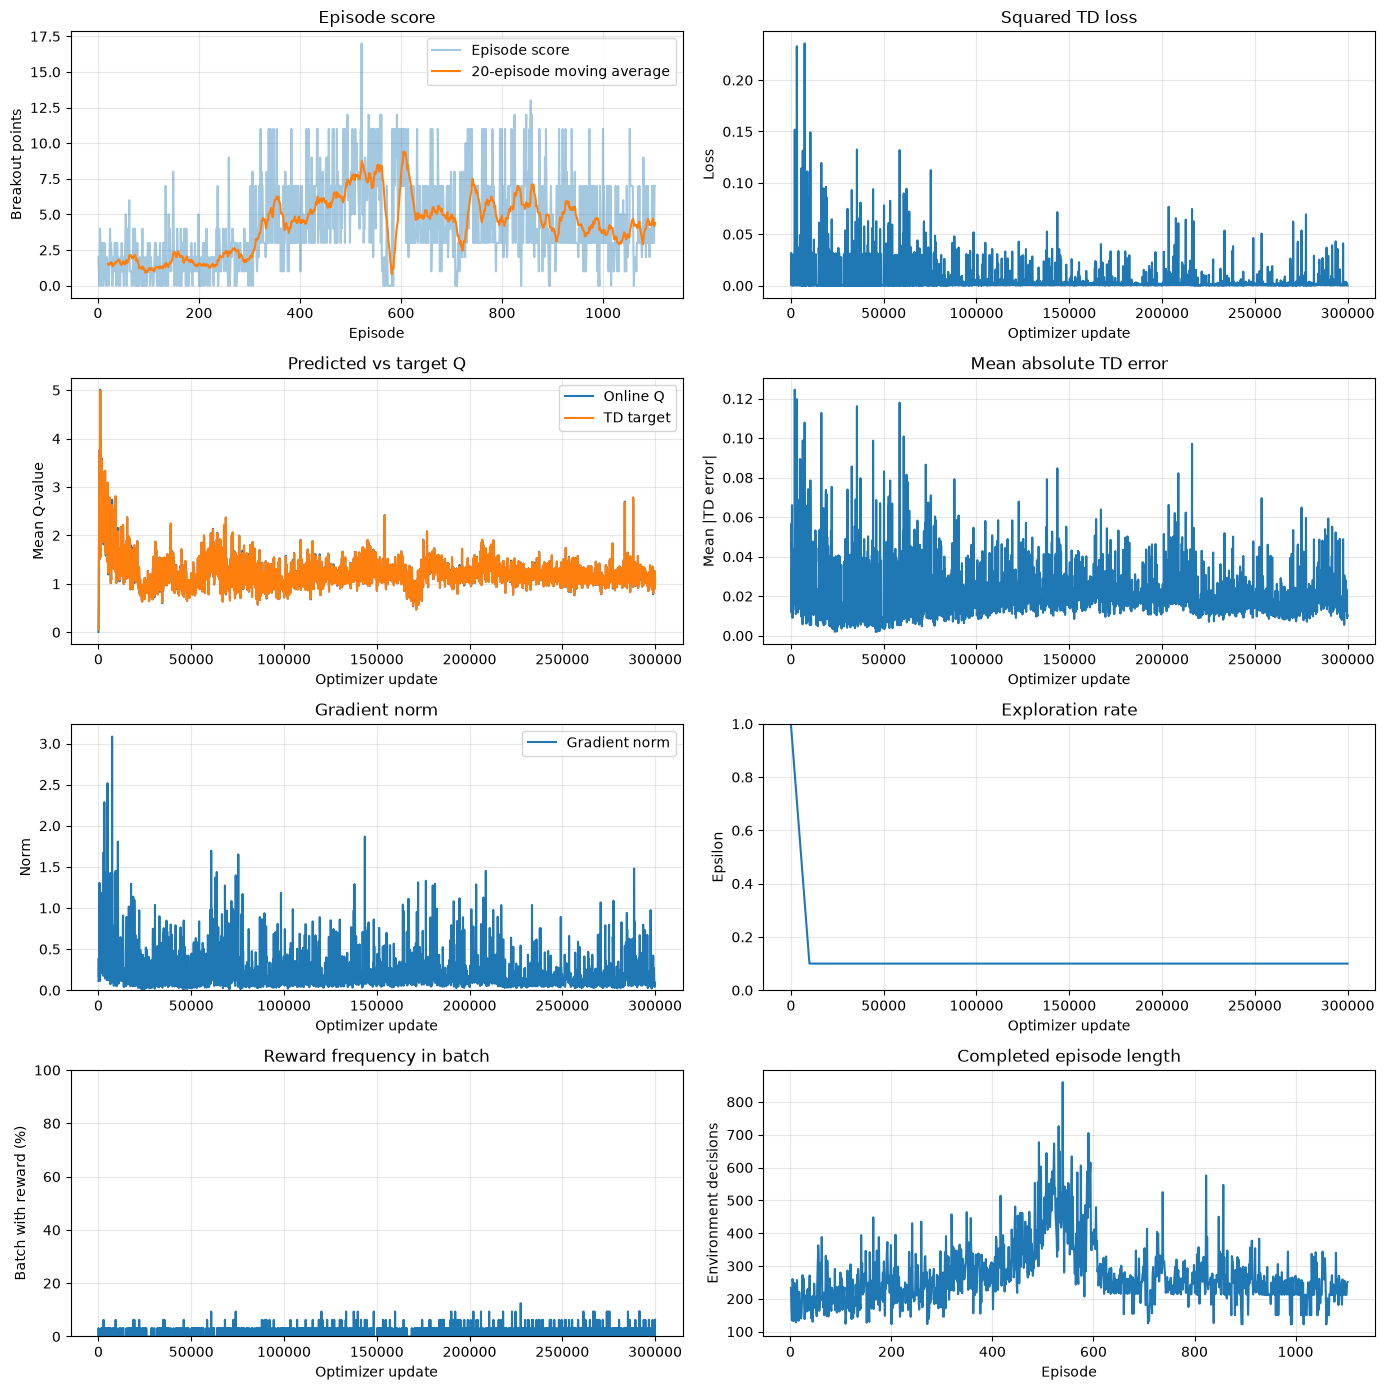

In [11]:
if optimization_steps:
    fig, axes = plt.subplots(4, 2, figsize=(14, 14))
    axes = axes.ravel()

    if episode_returns:
        episodes = np.arange(1, len(episode_returns) + 1)
        axes[0].plot(episodes, episode_returns, alpha=0.4, label="Episode score")
        window = min(20, len(episode_returns))
        moving = np.convolve(episode_returns, np.ones(window) / window, mode="valid")
        axes[0].plot(np.arange(window, len(episode_returns) + 1), moving,
                     label=f"{window}-episode moving average")
        axes[0].legend()
    axes[0].set(title="Episode score", xlabel="Episode", ylabel="Breakout points")

    updates = np.asarray(optimization_steps)
    axes[1].plot(updates, loss_history)
    axes[1].set(title="Squared TD loss", xlabel="Optimizer update", ylabel="Loss")
    axes[2].plot(updates, metric_history["q_mean"], label="Online Q")
    axes[2].plot(updates, metric_history["target_q_mean"], label="TD target")
    axes[2].set(title="Predicted vs target Q", xlabel="Optimizer update", ylabel="Mean Q-value")
    axes[2].legend()
    axes[3].plot(updates, metric_history["td_error"])
    axes[3].set(title="Mean absolute TD error", xlabel="Optimizer update", ylabel="Mean |TD error|")
    axes[4].plot(updates, metric_history["gradient_norm"], label="Gradient norm")
    axes[4].set(title="Gradient norm", xlabel="Optimizer update", ylabel="Norm")
    axes[4].set_ylim(
        0, max(1.0, max(metric_history["gradient_norm"], default=0.0) * 1.05)
    )
    axes[4].legend()
    axes[5].plot(updates, metric_history["epsilon"])
    axes[5].set(title="Exploration rate", xlabel="Optimizer update", ylabel="Epsilon")
    axes[5].set_ylim(0, 1)
    axes[6].plot(updates, metric_history["reward_rate"])
    axes[6].set(title="Reward frequency in batch", xlabel="Optimizer update", ylabel="Batch with reward (%)")
    axes[6].set_ylim(0, 100)
    axes[7].plot(np.arange(1, len(episode_lengths) + 1), episode_lengths)
    axes[7].set(title="Completed episode length", xlabel="Episode", ylabel="Environment decisions")

    for ax in axes:
        ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()
else:
    print("No optimizer updates were completed, so training metrics are not available.")

## 10. Evaluate with epsilon 0.05 and original rewards

Figure 2 evaluates for 10,000 steps with epsilon 0.05; Section 5.3 uses a fixed-step
budget. Here the budget counts agent decisions. No learning or replay writes occur.
Report the mean and standard deviation of completed games and separately report any
unfinished game's score, so a cutoff fragment cannot masquerade as a full episode.
If no game finishes, there is no completed-episode mean to report.

In [12]:
def evaluate_agent(num_steps=EVAL_STEPS):
    eval_env = make_env(seed=SEED + 1000)
    scores = []
    score, length = 0.0, 0
    try:
        state, info = eval_env.reset(seed=SEED + 1000)
        for decision in range(num_steps):
            action = select_action(state, EVAL_EPSILON, eval_env.action_space)
            state, reward, terminated, truncated, info = eval_env.step(action)
            score += float(reward)
            length += 1
            if terminated:
                scores.append(score)
                print(f"Completed game {len(scores)}: score={score:.1f}, decisions={length}")
            elif truncated:
                print(f"Time-limited game (excluded from mean): score={score:.1f}")
            if terminated or truncated:
                state, info = eval_env.reset()
                score, length = 0.0, 0
    finally:
        eval_env.close()
    if scores:
        print(f"Completed-game mean: {np.mean(scores):.2f} +/- {np.std(scores):.2f}")
    else:
        print("No complete games within the evaluation budget.")
    if length:
        print(f"Unfinished game: score={score:.1f} after {length} decisions (excluded from mean).")
    return scores

evaluation_scores = evaluate_agent(EVAL_STEPS if RUN_PROFILE == "paper" else 256)

Completed game 1: score=2.0, decisions=184
Completed game 2: score=1.0, decisions=150
Completed game 3: score=3.0, decisions=213
Completed game 4: score=1.0, decisions=150
Completed game 5: score=3.0, decisions=212
Completed game 6: score=0.0, decisions=122
Completed game 7: score=3.0, decisions=213
Completed game 8: score=2.0, decisions=181
Completed game 9: score=1.0, decisions=150
Completed game 10: score=0.0, decisions=122
Completed game 11: score=1.0, decisions=150
Completed game 12: score=1.0, decisions=150
Completed game 13: score=1.0, decisions=150
Completed game 14: score=3.0, decisions=210
Completed game 15: score=5.0, decisions=294
Completed game 16: score=3.0, decisions=212
Completed game 17: score=1.0, decisions=150
Completed game 18: score=1.0, decisions=150
Completed game 19: score=2.0, decisions=183
Completed game 20: score=3.0, decisions=213
Completed game 21: score=0.0, decisions=122
Completed game 22: score=3.0, decisions=212
Completed game 23: score=0.0, decisions=1

## 11. Record gameplay

Record 10,000 decisions using the same epsilon-0.05 policy as evaluation. FIRE is
chosen by the policy here too. Videos are recorded at the raw emulator frame rate
in a new timestamped directory; previous videos are preserved. This is a demonstration,
not evidence of matching the paper's reported Breakout score of 168.

In [13]:
video_dir = VIDEO_DIR / time.strftime("%Y%m%d-%H%M%S")
video_env = make_env(render_mode="rgb_array", video_folder=video_dir, seed=SEED + 2026)
max_steps = 10_000 if RUN_PROFILE == "paper" else 256
try:
    state, info = video_env.reset(seed=SEED + 2026)
    for _ in range(max_steps):
        action = select_action(state, EVAL_EPSILON, video_env.action_space)
        state, reward, terminated, truncated, info = video_env.step(action)
        if terminated or truncated:
            state, info = video_env.reset()
finally:
    video_env.close()

mp4_files = sorted(video_dir.glob("*.mp4"))
print("Videos saved to:", video_dir)
if mp4_files:
    display(Video(str(mp4_files[0]), embed=True, width=640))

Videos saved to: d:\Projects\IIT\Reinforcement-Learning-reimplementation\outputs\breakout_video_2013\20261029-143918
